# PEMS-BAY — the full story of the 2026-06-10 diffusion runs

This notebook walks through **everything we verified for PEMS-BAY** (as of 2026-06-11), in plain language:

1. **the pipeline** — what the model chain is, in one page.
2. **the residuals** — what is stored, the one normalization constant, heavy tails, and the train-vs-val gate (which PEMS-BAY fails *by design of the data*, not by a bug).
3. **the prior matrices** — the temporal covariance the diffusion noise uses, and the sensor graph.
4. **the noising process** — the FCPS schedule and an empirical check that the forward process does exactly what the math says.
5. **training** — all 6 runs (2 priors x 3 seeds): losses, in-training sample quality, distribution match.
6. **test results so far** — with a big caveat: a known eval bug contaminates every test number on disk.
7. **summary table** — every check, pass/fail/pending, one line each.

Quick facts: **325 sensors**, units are **mph** (traffic speed), horizon **H = 12 steps** of 5 minutes (one hour ahead). Seeds 42/43/44 were trained; **seed 42 is the display seed** here (seeds 43/44 agree on every number we checked — noted inline where it matters).

Role of this dataset in the thesis: PEMS-BAY is the agreed **limitation case study**. Its validation period is noisier than its training period (a real distribution step in the data), so a prior fitted on train is mis-scaled on val/test. We show that below rather than hide it.


In [1]:
# setup: this notebook is pems-bay only. seed 42 is the display seed.
dataset = "pemsbay"
seed = 42

import os, sys
while not os.path.exists("pyproject.toml"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as sps
from scipy.optimize import brentq
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

from src.utils import paths
from src.data.adjacency import load_adjacency, compute_normalized_laplacian
from src.diffusion.prior import load_prior, KAPPA_CAP, SPATIAL_FLATTEN
from src.diffusion.forward_fcps import FCPSSchedule, sample_R_t_given_R0, _rotate_to_eigenbasis

print("dataset:", dataset, "  display seed:", seed)
print("prior code flag SPATIAL_FLATTEN =", SPATIAL_FLATTEN,
      " -> the trained 'kronecker' prior is temporal-only (Sigma_S = I)")


dataset: pemsbay   display seed: 42
prior code flag SPATIAL_FLATTEN = True  -> the trained 'kronecker' prior is temporal-only (Sigma_S = I)


## 1. what the pipeline is (recap)

The model is a two-stage chain:

1. **backbone**: a Graph WaveNet takes the last hour of traffic and predicts the next hour, for every sensor. Its error is the **residual = truth − prediction**, stored in raw units (mph) with shape (windows, 325 sensors, 12 steps). The backbone's test MAE runs 5–14% above the literature targets (warned in the training logs); known, and acceptable for a residual study — and PEMS-BAY is the limitation set anyway.
2. **diffusion on residuals**: a diffusion model learns the *distribution* of those residuals, so we can turn the backbone's single point forecast into calibrated uncertainty. Before training, residuals are divided by **one global scalar** `sigma_r` (the masked std of the *train* residuals, frozen for val/test) — that is the entire normalization.
3. **the forward (noising) process** is an Ornstein–Uhlenbeck SDE that destroys the residual toward a chosen stationary covariance — the **prior**. Two arms are compared:
   - **"kronecker"** (the structured arm): stationary covariance carries the empirical *temporal* structure of the residuals, `Sigma_T` (12x12). In the 20260610 runs the *spatial* factor is flattened to the identity (`SPATIAL_FLATTEN = True`, so `Sigma_S = I`, gamma = 0) — it is a **temporal-only** prior. The graph-Laplacian spatial code is a dormant path reserved for a later structured-spatial A/B.
   - **isotropic** (the baseline): plain white noise, variance exactly 1 in the normalized space (per-mode precision theta = 1).
4. **training objective**: predict the clean residual from its noised version (x0-prediction), masked MSE in unit space, with diffusion time drawn uniformly from [1e-3, 1].
5. **sampling**: run the reverse process from pure prior noise, conditioned on the backbone's prediction window — each run gives one plausible residual; many runs give a predictive distribution.

Everything below checks this chain piece by piece on PEMS-BAY.


## 2. the residuals — what is on disk and is it sound?

Each split (`train` / `val` / `test`) is one `.npz` under `results/residuals/pemsbay/seed42/` with:

| key | shape | what it is |
|---|---|---|
| `residuals` | (B, N, H) | truth − backbone prediction, raw mph. **the thing we model.** |
| `y_pred` | (B, N, H) | the backbone's forecast (truth = `y_pred + residuals`) |
| `mask` | (B, N, H) | True = real observation, False = missing |
| `mean`, `std` | scalars | z-score stats of the backbone's *input* (not the residual normalization) |

Residuals are stored as float16 to save disk — verified numerically harmless (all statistics below are computed in float64 and match the float32/64 pipeline). First check: shapes, missing data, NaN/inf, and the one normalization constant `sigma_r`.


In [2]:
npz = {sp: np.load(paths.residual_npz(dataset, sp, seed)) for sp in ["train", "val", "test"]}

print("keys in train.npz:", npz["train"].files)
nan_inf_total = 0
for sp in ["train", "val", "test"]:
    d = npz[sp]
    R_, M_ = d["residuals"], d["mask"]
    n_bad = int(np.isnan(R_).sum()) + int(np.isinf(R_).sum())
    nan_inf_total += n_bad
    print(f"{sp:5s}  residuals {str(R_.shape):18s} {str(R_.dtype):8s} "
          f"mask valid frac {M_.astype(bool).mean():.4f}   nan+inf {n_bad}")

R_tr = npz["train"]["residuals"]          # float16 on disk, raw mph
M_tr = npz["train"]["mask"].astype(bool)
B, N, H = R_tr.shape
print(f"\ntrain: B = {B} windows,  N = {N} sensors,  H = {H} steps (5 min each)")
print("backbone-input z-score stats: mean =", round(float(npz['train']['mean']), 3),
      " std =", round(float(npz['train']['std']), 3))

# the single normalization constant of the whole diffusion stage:
# sigma_r = masked std of the TRAIN residuals, frozen for val/test
sigma_r = float(R_tr[M_tr].astype(np.float64).std())
print(f"\nsigma_r = {sigma_r:.4f} mph   "
      f"(training log printed 3.5537 -> match: {abs(sigma_r - 3.5537) < 5e-4})")


keys in train.npz: ['residuals', 'y_pred', 'mask', 'mean', 'std']


train  residuals (36458, 325, 12)   float16  mask valid frac 1.0000   nan+inf 0


val    residuals (5189, 325, 12)    float16  mask valid frac 0.9999   nan+inf 0


test   residuals (10400, 325, 12)   float16  mask valid frac 0.9999   nan+inf 0



train: B = 36458 windows,  N = 325 sensors,  H = 12 steps (5 min each)
backbone-input z-score stats: mean = 62.737  std = 9.437



sigma_r = 3.5537 mph   (training log printed 3.5537 -> match: True)


**What this means:** the files are clean — zero NaN/inf anywhere, and PEMS-BAY has essentially no missing data (mask is fully valid; METR-LA is the messy one). The normalization is **one number**: every residual is divided by `sigma_r` ≈ 3.55 mph, computed on train only and reused verbatim for val/test, so nothing leaks from val. For reference, the other datasets' seed-42 values are 6.1622 (METR-LA) and 28.5671 (PEMS08F, flow units).

One subtlety worth pausing on: dividing by a single scalar makes the *pooled* train std exactly 1.0 — but **not** the per-horizon std. The error at +5 min is far smaller than at +60 min, and a global scalar cannot flatten that. Let's look.


normalized per-horizon std (raw std / sigma_r):
split    h1     h2     h3     h4     h5     h6     h7     h8     h9     h10    h11    h12 
train   0.43  0.62  0.76  0.88  0.96  1.02  1.07  1.11  1.15  1.18  1.21  1.24
val     0.46  0.68  0.84  0.97  1.06  1.14  1.20  1.25  1.29  1.33  1.36  1.40
test    0.46  0.66  0.81  0.93  1.01  1.08  1.14  1.18  1.22  1.25  1.28  1.31

pooled train std / sigma_r = 1.00 by construction; per horizon it runs 0.43 (h1) to 1.24 (h12)


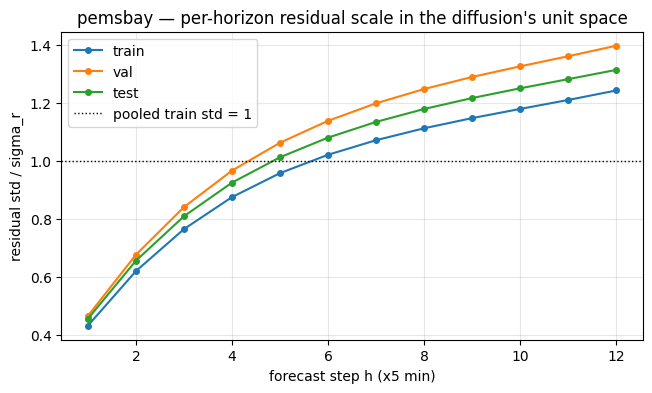

In [3]:
def std_h_masked(d):
    R_, M_ = d["residuals"], d["mask"].astype(bool)
    return np.array([R_[:, :, h][M_[:, :, h]].astype(np.float64).std() for h in range(H)])

stds = {sp: std_h_masked(npz[sp]) for sp in ["train", "val", "test"]}

print("normalized per-horizon std (raw std / sigma_r):")
print("split  " + " ".join(f"  h{h+1:<3d}" for h in range(H)))
for sp in ["train", "val", "test"]:
    print(f"{sp:5s}  " + " ".join(f"{x/sigma_r:5.2f}" for x in stds[sp]))
print(f"\npooled train std / sigma_r = 1.00 by construction; per horizon it runs "
      f"{stds['train'][0]/sigma_r:.2f} (h1) to {stds['train'][-1]/sigma_r:.2f} (h12)")

plt.figure(figsize=(7.5, 4))
for sp, c in [("train", "C0"), ("val", "C1"), ("test", "C2")]:
    plt.plot(range(1, H + 1), stds[sp] / sigma_r, "o-", color=c, ms=4, label=sp)
plt.axhline(1.0, color="k", ls=":", lw=1, label="pooled train std = 1")
plt.xlabel("forecast step h (x5 min)")
plt.ylabel("residual std / sigma_r")
plt.title(dataset + " — per-horizon residual scale in the diffusion's unit space")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


**What this means:** in the diffusion's working space the residual std climbs from **~0.43 at h1 to ~1.24 at h12** — a ~3x spread that the single scalar deliberately leaves in place. Encoding exactly this spread is the job of the temporal prior's diagonal `D_H` (section 3): the structured arm tells the noise process "the +5 min error is small, the +60 min error is large", while the isotropic arm pretends every step has variance 1.

Also visible already: the **val curve sits above the train curve at every horizon**. Hold that thought — it is the gate failure coming up below.

### are the residuals gaussian? (no — heavy tails)

The structured prior is currently a *gaussian* with the right covariance. Whether a gaussian is even the right family is exactly the question behind the planned structured heavy-tailed pivot. The cheap, robust diagnostic is the **excess kurtosis** (gaussian = 0) of the raw residuals, plus a histogram on a log scale so the tails are visible.


train residuals: mean -0.1733  std 3.5537  skew -2.30  excess kurtosis 39.9
moment-implied student-t  nu = 4 + 6/kurtosis = 4.15   (gaussian would be 0 kurtosis)


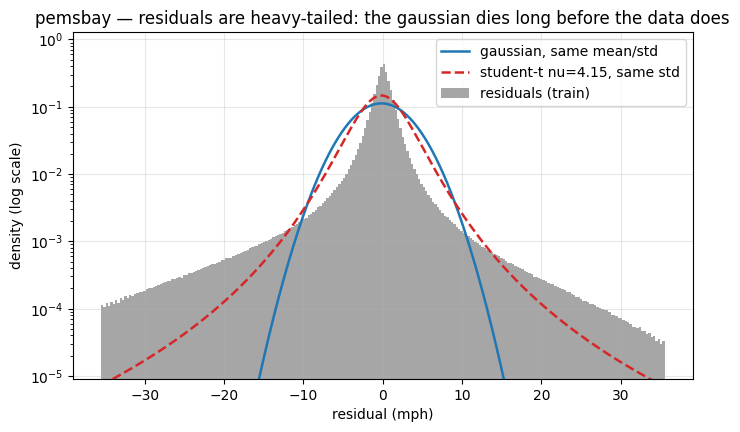

In [4]:
v = R_tr[M_tr].astype(np.float32)        # all valid train residuals, raw mph
mean = float(v.mean(dtype=np.float64))
m2 = m3 = m4 = 0.0
CH = 20_000_000                          # chunked so we never hold a 2nd float64 copy of 142M values
for i in range(0, v.size, CH):
    c = v[i:i + CH].astype(np.float64) - mean
    m2 += (c * c).sum(); m3 += (c * c * c).sum(); m4 += (c * c * c * c).sum()
m2, m3, m4 = m2 / v.size, m3 / v.size, m4 / v.size
std = float(np.sqrt(m2))
skew = float(m3 / std**3)
exkurt = float(m4 / std**4 - 3.0)
nu_implied = 4.0 + 6.0 / exkurt          # moment match: excess kurtosis of student-t is 6/(nu-4)
print(f"train residuals: mean {mean:+.4f}  std {std:.4f}  skew {skew:+.2f}  excess kurtosis {exkurt:.1f}")
print(f"moment-implied student-t  nu = 4 + 6/kurtosis = {nu_implied:.2f}   (gaussian would be 0 kurtosis)")

edges = np.linspace(-10 * std, 10 * std, 241)
cnt, _ = np.histogram(v, bins=edges)
ctr = 0.5 * (edges[:-1] + edges[1:])
dens = cnt / (v.size * (edges[1] - edges[0]))

plt.figure(figsize=(8, 4.5))
plt.bar(ctr, dens, width=edges[1] - edges[0], color="0.65", label="residuals (train)")
xx = np.linspace(edges[0], edges[-1], 600)
plt.plot(xx, sps.norm.pdf(xx, mean, std), "C0-", lw=1.8, label="gaussian, same mean/std")
tsc = std * np.sqrt((nu_implied - 2) / nu_implied)
plt.plot(xx, sps.t.pdf(xx, df=nu_implied, loc=mean, scale=tsc), "C3--", lw=1.8,
         label=f"student-t nu={nu_implied:.2f}, same std")
plt.yscale("log")
plt.ylim(max(dens[dens > 0].min() * 0.3, 1e-12), dens.max() * 3)
plt.xlabel("residual (mph)"); plt.ylabel("density (log scale)")
plt.title(dataset + " — residuals are heavy-tailed: the gaussian dies long before the data does")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
del v


**What this means:** excess kurtosis ≈ 40 is *very* far from gaussian — on the log scale the gaussian curve underestimates the tail density by orders of magnitude, while a student-t with the moment-matched **nu ≈ 4.15** tracks the data much further out. Across the three datasets the same calculation gives nu in **[4.15, 4.31]**, neatly bracketing the hypothesized nu ≈ 4.2 of the structured heavy-tailed pivot. This is the empirical motivation for replacing the gaussian prior with a Student-t one.

Two honest caveats: (1) the residuals have a strong **left skew** (≈ −2.3 here: sudden speed *drops* — incidents and jam onsets — that the backbone misses), and a symmetric t does not capture asymmetry; (2) nu here is moment-matched, not maximum-likelihood fitted, so treat it as a scale-of-magnitude, not a final parameter.

### the train-vs-val variance gate (the one PEMS-BAY fails)

The prior is fitted on train. For it to be the right prior at val/test time, the residual *scale* must be stable across splits. The project gate: per horizon, the second moment `delta_h = mean(residual_h^2)` must satisfy `|delta_h(val) / delta_h(train) − 1| < 0.10` for **all** 12 horizons.


 h    delta_train   delta_val   val/train - 1
 1        2.351       2.729     +16.1%   XX
 2        4.854       5.781     +19.1%   XX
 3        7.397       8.940     +20.9%   XX
 4        9.692      11.823     +22.0%   XX
 5       11.616      14.306     +23.2%   XX
 6       13.213      16.426     +24.3%   XX
 7       14.549      18.223     +25.3%   XX
 8       15.693      19.760     +25.9%   XX
 9       16.702      21.105     +26.4%   XX
10       17.643      22.333     +26.6%   XX
11       18.588      23.537     +26.6%   XX
12       19.610      24.813     +26.5%   XX

worst horizon: 0.2662  ->  gate (<0.10 for all h): FAIL
seed 42: worst |val/train - 1| = 0.2662  (FAIL)
seed 43: worst |val/train - 1| = 0.2563  (FAIL)
seed 44: worst |val/train - 1| = 0.2567  (FAIL)



overall val std / train std = 1.117  -> validation residuals are ~12% noisier than training


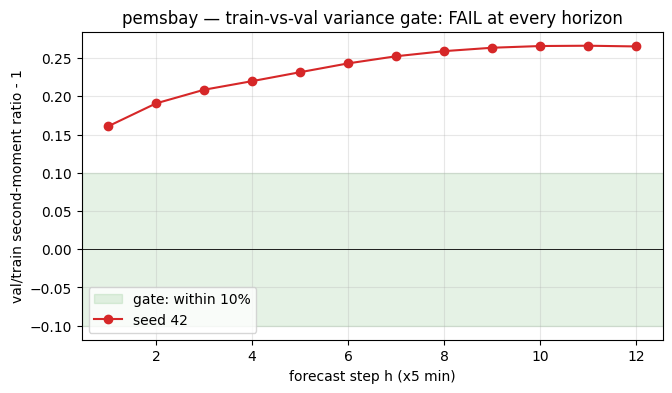

In [5]:
def delta_h_masked(d):
    # delta_h = masked mean of R_h^2 (second moment) — the project's scale measure
    R_, M_ = d["residuals"], d["mask"].astype(bool)
    return np.array([(R_[:, :, h][M_[:, :, h]].astype(np.float64) ** 2).mean() for h in range(H)])

delta_tr = delta_h_masked(npz["train"])
delta_vl = delta_h_masked(npz["val"])
ratio = delta_vl / delta_tr - 1.0
gate_worst = float(np.abs(ratio).max())
gate_pass = bool(gate_worst < 0.10)

print(" h    delta_train   delta_val   val/train - 1")
for h in range(H):
    mark = "ok" if abs(ratio[h]) < 0.10 else "XX"
    print(f"{h+1:>2}    {delta_tr[h]:>9.3f}   {delta_vl[h]:>9.3f}   {ratio[h]:>+8.1%}   {mark}")
print(f"\nworst horizon: {gate_worst:.4f}  ->  gate (<0.10 for all h): {'PASS' if gate_pass else 'FAIL'}")

# the same number for all three seeds, from the diagnostic.json written at extraction time
for s in [42, 43, 44]:
    diag = json.loads((paths.residual_dir(dataset, s) / "diagnostic.json").read_text())
    r = np.abs(np.array(diag["delta_val"]) / np.array(diag["delta_train"]) - 1.0)
    print(f"seed {s}: worst |val/train - 1| = {r.max():.4f}  "
          f"({'PASS' if r.max() < 0.10 else 'FAIL'})")

vstd = float(npz["val"]["residuals"][npz["val"]["mask"].astype(bool)].astype(np.float64).std())
print(f"\noverall val std / train std = {vstd / sigma_r:.3f}  "
      f"-> validation residuals are ~{(vstd / sigma_r - 1) * 100:.0f}% noisier than training")

plt.figure(figsize=(7.5, 4))
plt.axhspan(-0.10, 0.10, color="green", alpha=0.10, label="gate: within 10%")
plt.axhline(0, color="k", lw=0.6)
plt.plot(range(1, H + 1), ratio, "o-", color="C3", label="seed 42")
plt.xlabel("forecast step h (x5 min)")
plt.ylabel("val/train second-moment ratio - 1")
plt.title(dataset + " — train-vs-val variance gate: FAIL at every horizon")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


**What this means:** PEMS-BAY **fails the gate at every horizon, on all three seeds** (worst ≈ 0.26; the gate allows 0.10). The validation period is simply a noisier stretch of traffic than the training period — the residual std is ~12% larger on val. METR-LA and PEMS08F both pass comfortably (worst 0.070 and 0.051).

The consequence is mechanical and predictable: the prior's scale (fitted on train) is **~12% too small for val/test**, so any prior-faithful sampler should *under-cover* there — its 90% intervals will catch fewer than 90% of outcomes. This is a property of the data split, not a modeling bug, and it is exactly why PEMS-BAY is positioned as the **limitation case study** in the thesis (METR-LA and PEMS08F carry the headline results).


## 3. the prior matrices

The structured arm's stationary covariance is, on paper, a Kronecker product `Sigma = Sigma_T ⊗ Sigma_S`. In the 20260610 runs the spatial factor is **flattened to the identity** (`SPATIAL_FLATTEN = True` in `src/diffusion/prior.py`: `Sigma_S = I`, gamma = 0), so what was actually trained is a **temporal-only** structured prior. The graph code below is the dormant path for the future structured-spatial A/B — we still health-check it.

The temporal factor is built from the normalized train residuals:

- `D_H` — the per-horizon second moment (the 0.43² → 1.24² growth from section 2),
- `R_H` — the empirical correlation between horizons (if the model is too high at +5 min, is it also too high at +10?),
- `Sigma_T = D_H^{1/2} R_H D_H^{1/2}`, then its eigenvalues are **floored so the condition number stays ≤ kappa = 40** — otherwise near-singular horizon correlations would force the noising process to cover an absurd range of time scales.

The isotropic baseline is exactly `sigma² = 1` in unit space (theta = 1 for every mode): same total noise energy, zero structure.


Sigma_T symmetric (max asym 2.2e-16) and PSD: True
delta_h (unit space): h1 0.186 -> h12 1.553  (x8.3 growth)
eigenvalues raw: [0.0520, 8.372]  ->  cond = 161
after the eigenvalue floor (kappa cap = 40): cond = 40,  modes floored: 8/12
per-mode precision theta = 1/mu (since Sigma_S = I): theta_min = 0.1194, theta_max = 4.778


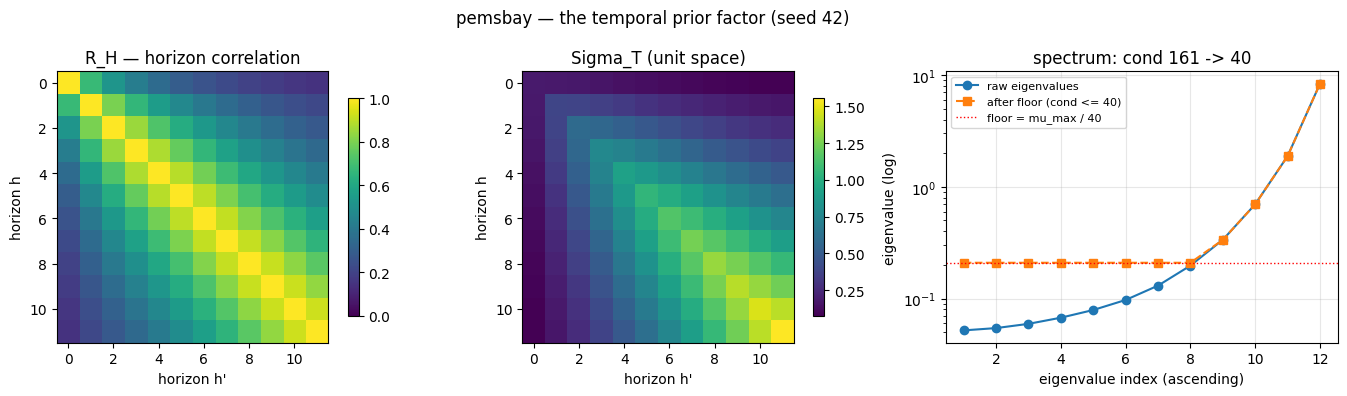

In [6]:
prior = load_prior(dataset, "kronecker", seed)   # fits from the train residuals, exactly as training did

D_sqrt = np.sqrt(prior.delta_h)                  # delta_h lives in unit space (= variance per horizon)
Sigma_T = (D_sqrt[:, None] * prior.R_H) * D_sqrt[None, :]
mu_raw = np.linalg.eigvalsh(Sigma_T)
cond_raw = float(mu_raw.max() / mu_raw.min())
cond_capped = float(prior.mu_T.max() / prior.mu_T.min())
n_floored = int((mu_raw < mu_raw.max() / KAPPA_CAP).sum())
sym_err = float(np.abs(Sigma_T - Sigma_T.T).max())
psd = bool(mu_raw.min() > 0)

print(f"Sigma_T symmetric (max asym {sym_err:.1e}) and PSD: {psd}")
print(f"delta_h (unit space): h1 {prior.delta_h[0]:.3f} -> h12 {prior.delta_h[-1]:.3f}"
      f"  (x{prior.delta_h[-1] / prior.delta_h[0]:.1f} growth)")
print(f"eigenvalues raw: [{mu_raw.min():.4f}, {mu_raw.max():.3f}]  ->  cond = {cond_raw:.0f}")
print(f"after the eigenvalue floor (kappa cap = {KAPPA_CAP:.0f}): cond = {cond_capped:.0f},"
      f"  modes floored: {n_floored}/12")
print(f"per-mode precision theta = 1/mu (since Sigma_S = I): "
      f"theta_min = {prior.theta.min():.4f}, theta_max = {prior.theta.max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
im = axes[0].imshow(prior.R_H, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[0].set_title("R_H — horizon correlation")
axes[0].set_xlabel("horizon h'"); axes[0].set_ylabel("horizon h")
im = axes[1].imshow(Sigma_T, cmap="viridis")
plt.colorbar(im, ax=axes[1], shrink=0.8)
axes[1].set_title("Sigma_T (unit space)")
axes[1].set_xlabel("horizon h'"); axes[1].set_ylabel("horizon h")
axes[2].semilogy(range(1, 13), mu_raw, "o-", label="raw eigenvalues")
axes[2].semilogy(range(1, 13), np.sort(prior.mu_T), "s--", label="after floor (cond <= 40)")
axes[2].axhline(mu_raw.max() / KAPPA_CAP, color="r", ls=":", lw=1, label="floor = mu_max / 40")
axes[2].set_xlabel("eigenvalue index (ascending)"); axes[2].set_ylabel("eigenvalue (log)")
axes[2].set_title(f"spectrum: cond {cond_raw:.0f} -> {cond_capped:.0f}")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.suptitle(dataset + " — the temporal prior factor (seed 42)")
plt.tight_layout()
plt.show()


**What this means:** the matrix is well-formed (symmetric, positive definite) and shows exactly the structure we expect — variance growing ~8x from h1 to h12 along the diagonal, and strong, smoothly decaying correlation between neighbouring horizons.

The interesting number is the **condition: raw 161, capped to 40 with 8 of 12 eigenvalues floored**. PEMS-BAY is the *only* dataset where the cap binds (METR-LA and PEMS08F sit below 40 raw): its horizon correlations are so strong that `R_H` is nearly singular. The floor is deliberate — without it the slowest noise mode would need an enormous schedule budget (section 4). Seed stability is fine: `Sigma_T` differs by at most ~1.4% (relative Frobenius) across seeds 42/43/44.

### the sensor graph (dormant for these runs, but health-checked)

One gotcha to be aware of before reading any "number of components" claim: the normalized Laplacian code guards against zero-degree sensors (`d > 0` in `src/data/adjacency.py`), which turns an isolated sensor's row into an identity row. An isolated sensor therefore shows up at **eigenvalue 1**, in the middle of the spectrum — *not* as a second zero eigenvalue. Counting zero eigenvalues will happily report "1 component" no matter how many sensors are stranded. The truth comes from an actual graph traversal (BFS / `connected_components`). We show both.


sensors: 325   zero-degree (isolated): 6
BFS connected components: 7   sizes: [319, 1, 1, 1, 1, 1, 1]
zero Laplacian eigenvalues (<1e-8), the naive component count: 1  <- misleading!
lambda_2 of the full spectrum: 0.0039


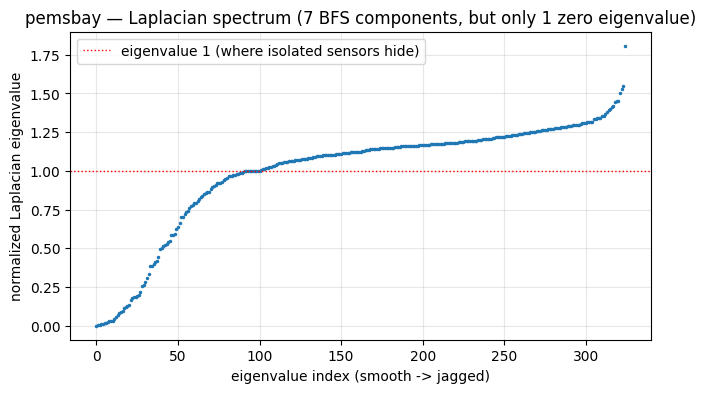

In [7]:
import warnings

with warnings.catch_warnings():
    # the d>0 guard in adjacency.py raises a harmless divide-by-zero warning for the
    # 6 isolated sensors (that guard is exactly the gotcha discussed above); the pickle
    # load also emits a numpy deprecation notice. both silenced for readability.
    warnings.simplefilter("ignore")
    with np.errstate(divide="ignore"):
        A_raw = load_adjacency(dataset).astype(np.float64)
        L = compute_normalized_laplacian(A_raw)

A = A_raw.copy(); np.fill_diagonal(A, 0.0); A = 0.5 * (A + A.T)   # what the laplacian code does
deg = A.sum(axis=1)

n_comp, labels = connected_components(csr_matrix(A > 0), directed=False)
sizes = np.sort(np.bincount(labels))[::-1]
n_isolated = int((deg == 0).sum())

ev = np.linalg.eigvalsh(L)
n_zero = int((ev < 1e-8).sum())

print(f"sensors: {A.shape[0]}   zero-degree (isolated): {n_isolated}")
print(f"BFS connected components: {n_comp}   sizes: {sizes.tolist()}")
print(f"zero Laplacian eigenvalues (<1e-8), the naive component count: {n_zero}  <- misleading!")
print(f"lambda_2 of the full spectrum: {ev[1]:.4f}")

plt.figure(figsize=(7.5, 4))
plt.plot(ev, ".", ms=3)
plt.axhline(1.0, color="r", ls=":", lw=1, label="eigenvalue 1 (where isolated sensors hide)")
plt.xlabel("eigenvalue index (smooth -> jagged)")
plt.ylabel("normalized Laplacian eigenvalue")
plt.title(dataset + f" — Laplacian spectrum ({n_comp} BFS components, but only {n_zero} zero eigenvalue)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


**What this means:** the graph is a **giant component of 319 sensors plus 6 isolated sensors** (7 BFS components) — yet the eigenvalue count says "1 component" because those 6 sensors sit at eigenvalue 1, exactly as the gotcha predicts. This is **benign**, not fragmentation: every non-giant piece is a single stranded sensor (1.8% of nodes), each of which would simply get an independent, temporal-only prior under the structured-spatial arm.

For the trained 20260610 runs this is moot anyway (`Sigma_S = I`; the graph only feeds the denoiser network as an input feature). It must be repaired before the structured-spatial A/B, though — stranded sensors get no spatial information at all.


## 4. the noising process (FCPS schedule) — and proof it works

In the prior's eigenbasis every mode k decays independently: signal shrinks as `exp(-c̄(t)·theta_k)` and noise grows toward the stationary variance `1/theta_k`, where `c̄(t)` is the accumulated noising budget and `c̄(T) = c_0`. The FCPS schedule shapes `c(t)` so slow (low-precision, high-variance) modes keep their signal until late t — they only mix near t = T.

The one knob is `c_0`, and here is a trap we explicitly verified: **training ignores the `--c-0` CLI flag** and auto-derives `c_0 = 5 / theta_min` (`FCPSSchedule.for_prior`), which guarantees the mixing condition `2·c̄(T)·theta_min = 10` — twice the required 5 — *by construction*. The `config.json` saved next to each checkpoint still records the ignored CLI default `c_0 = 20000`. That stale number is harmless for training but is the root of the eval bug in section 6.


config.json c_0 = 20000   <- the IGNORED cli default
auto-derived  c_0 = 5/theta_min = 41.86   (training log printed 41.9)
mixing condition 2*c_bar(T)*theta_min = 10.00   (needs >= 5; margin x2.0 by construction)


isotropic arm: theta = 1.00 everywhere -> c_0 = 5.00

slowest mode 99%-mixed at t* = 0.907, fastest at t* = 0.568  (slow modes hold signal until late t — the FCPS design)
under the buggy eval schedule (c_0 = 20000, 478x hotter) the slowest mode is already mixed by t* = 0.420 — see section 6


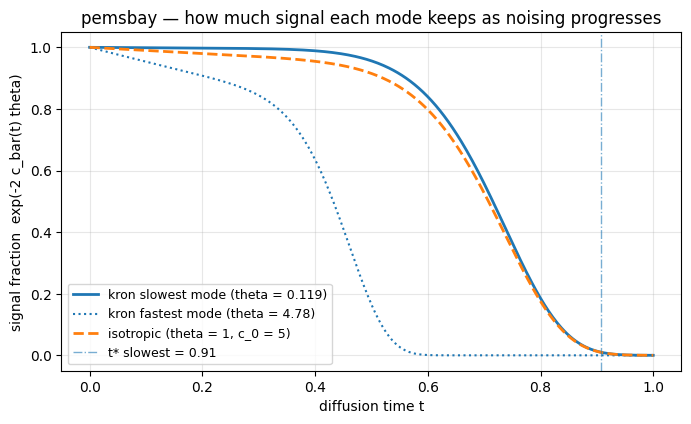

In [8]:
sch = FCPSSchedule.for_prior(prior)              # exactly what train_diffusion.py builds
theta_min, theta_max = float(prior.theta.min()), float(prior.theta.max())
mix_lhs = 2.0 * float(sch.c_bar(sch.T)) * theta_min

cfg = json.loads(Path(f"results/diffusion/20260610/{dataset}/kronecker/seed{seed}/config.json").read_text())
print(f"config.json c_0 = {cfg['c_0']:.0f}   <- the IGNORED cli default")
print(f"auto-derived  c_0 = 5/theta_min = {sch.c_0:.2f}   (training log printed 41.9)")
print(f"mixing condition 2*c_bar(T)*theta_min = {mix_lhs:.2f}   "
      f"(needs >= 5; margin x{mix_lhs / 5:.1f} by construction)")

p_iso = load_prior(dataset, "isotropic", seed)
sch_iso = FCPSSchedule.for_prior(p_iso)
print(f"isotropic arm: theta = {p_iso.theta.min():.2f} everywhere -> c_0 = {sch_iso.c_0:.2f}")

def t_star(theta, schedule):
    # the time where a mode is 99% mixed in variance: exp(-2 c_bar(t) theta) = 0.01
    target = np.log(100.0) / (2.0 * theta)
    return brentq(lambda t: float(schedule.c_bar(t)) - target, 0.0, schedule.T)

tstar_slow, tstar_fast = t_star(theta_min, sch), t_star(theta_max, sch)
sch_bug = FCPSSchedule(c_min=0.05, c_0=20000.0, alpha=7.0, T=1.0)
tstar_bug = t_star(theta_min, sch_bug)
print(f"\nslowest mode 99%-mixed at t* = {tstar_slow:.3f}, fastest at t* = {tstar_fast:.3f}"
      "  (slow modes hold signal until late t — the FCPS design)")
print(f"under the buggy eval schedule (c_0 = 20000, {20000 / sch.c_0:.0f}x hotter) the slowest mode "
      f"is already mixed by t* = {tstar_bug:.3f} — see section 6")

tt = np.linspace(0, 1, 400)
cb = np.asarray(sch.c_bar(tt))
plt.figure(figsize=(8, 4.4))
plt.plot(tt, np.exp(-2 * cb * theta_min), "C0-", lw=2, label=f"kron slowest mode (theta = {theta_min:.3f})")
plt.plot(tt, np.exp(-2 * cb * theta_max), "C0:", lw=1.5, label=f"kron fastest mode (theta = {theta_max:.2f})")
plt.plot(tt, np.exp(-2 * np.asarray(sch_iso.c_bar(tt)) * 1.0), "C1--", lw=2,
         label="isotropic (theta = 1, c_0 = 5)")
plt.axvline(tstar_slow, color="C0", ls="-.", lw=1, alpha=0.6, label=f"t* slowest = {tstar_slow:.2f}")
plt.xlabel("diffusion time t")
plt.ylabel("signal fraction  exp(-2 c_bar(t) theta)")
plt.title(dataset + " — how much signal each mode keeps as noising progresses")
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.show()


**What this means:** the schedule is healthy and matches the training logs digit-for-digit (`c_0` ≈ 41.9 kron, 5.0 iso; seeds 43/44: 42.1 / 41.6). The mixing condition holds at exactly 2x margin because `for_prior` constructs it that way; the slowest temporal mode is 99% mixed only at t* ≈ 0.91 — the intended FCPS behaviour, slow modes keep their structure for most of the trajectory.

### does the implementation actually match the math?

The closed form says: at time t, mode k should have mean `exp(-c̄(t)·theta_k)·(its start value)` and variance `(1 − exp(-2·c̄(t)·theta_k))/theta_k`. We now push real validation residuals through the *actual training code path* (`sample_R_t_given_R0`) and compare empirical means/variances against that formula, pooled per horizon. To keep this cell fast we subsample: **256 val windows, 3 t-values, 4 noise draws** (the full adversarial suite ran 512 windows x 8 draws x 5 t-values on all three datasets and both priors = 360 tests; worst pooled z there was 3.33 — pure Monte-Carlo noise).


In [9]:
# np.einsum with optimize=True routes the rotations through BLAS — identical numbers, much faster
_einsum = np.einsum
np.einsum = lambda *a, **k: _einsum(*a, **{"optimize": True, **k})

rv = npz["val"]["residuals"].astype(np.float64) / sigma_r       # unit space, like training
mv = npz["val"]["mask"].astype(bool)
rv[~mv] = 0.0                                                    # conditional check is exact for any R0

rng = np.random.default_rng(0)
idx = np.sort(rng.choice(rv.shape[0], size=256, replace=False))
R0 = rv[idx]
B0 = R0.shape[0]
del rv

# t = 0 must return R0 exactly (no noise has been applied yet)
X0 = sample_R_t_given_R0(R0[:8], 0.0, prior, sch, np.random.default_rng(1))
print(f"t=0 exactness: max abs err = {np.abs(X0 - R0[:8]).max():.2e}")

C0 = _rotate_to_eigenbasis(R0, prior)
scc = (C0 ** 2).sum(axis=0)
REPS = 4
rows = []
for t in [0.5, 0.9, 1.0]:
    cbar = float(sch.c_bar(t))
    Hth = np.exp(-prior.theta * cbar)                            # theory: mean decay per mode
    varth = (1 - np.exp(-2 * prior.theta * cbar)) / prior.theta  # theory: noise variance per mode
    sxc = np.zeros((N, H)); sr2 = np.zeros((N, H))
    for _ in range(REPS):
        Xt = sample_R_t_given_R0(R0, t, prior, sch, rng)         # the actual training code path
        Xe = _rotate_to_eigenbasis(Xt, prior)
        sxc += (Xe * C0).sum(axis=0)
        sr2 += ((Xe - Hth * C0) ** 2).sum(axis=0)
    # pool per horizon (theta is constant across sensors here, so all N modes share one truth)
    H_emp = sxc.sum(0) / (REPS * scc.sum(0))
    var_emp = sr2.sum(0) / (REPS * B0 * N)
    zH = np.abs(H_emp - Hth[0]) / np.sqrt(varth[0] / (REPS * scc.sum(0)))
    zV = np.abs(var_emp / varth[0] - 1.0) / np.sqrt(2.0 / (REPS * B0 * N))
    rows.append((t, float(np.abs(H_emp - Hth[0]).max()), float(zH.max()),
                 float(np.abs(var_emp / varth[0] - 1).max()), float(zV.max())))

print("\n  t    max|dH| (mean decay)   z(mean)   max rel dVar   z(var)")
for t, dh, zh, dv, zv2 in rows:
    print(f"{t:4.1f}        {dh:.2e}          {zh:5.2f}      {dv:.2e}    {zv2:5.2f}")
worst_z = max(max(r[2], r[4]) for r in rows)
print(f"\nworst pooled z = {worst_z:.2f}   "
      "(72 tests here -> expected worst ~2.9 under a perfect sampler; pass < 4.5)")
np.einsum = _einsum


t=0 exactness: max abs err = 1.07e-14



  t    max|dH| (mean decay)   z(mean)   max rel dVar   z(var)
 0.5        5.07e-03           1.93      4.16e-03     1.70
 0.9        3.64e-03           1.89      8.25e-03     3.37
 1.0        4.80e-03           2.02      4.61e-03     1.88

worst pooled z = 3.37   (72 tests here -> expected worst ~2.9 under a perfect sampler; pass < 4.5)


**What this means:** the implementation matches the closed form to **Monte-Carlo precision** — every deviation is the size statistics says it should be if the sampler were perfect. At t = T the empirical covariance is the stationary one (the full suite also verified off-diagonal leakage is indistinguishable from the analytic null, i.e. no basis/index bugs).

Historical note for completeness: an einsum index bug (`'bih'` → `'bij'`) in the *torch* forward sampler was found and fixed on 2026-06-01 (commit `ac391e9`, with a regression test). Checkpoints from before that fix are invalid; **all 20260610 runs contain the fix** — the check above is the independent empirical confirmation.


## 5. training — all 6 PEMS-BAY runs

Six runs: {kronecker, isotropic} x seeds {42, 43, 44}, experiment tag `20260610`, up to 200 epochs with early stopping (patience 15). Everything below is parsed from the slurm training logs (the largest `.out` per run directory is the real attempt; smaller ones died at epoch ≤ 1 and restarted from scratch).

The loss is **x0-prediction masked MSE in unit space**. The natural yardstick is the **predict-zero baseline**: a model that always outputs "residual = 0" scores ~1.0 on train by construction (the data has unit variance), and on *val* it scores the val/train variance ratio — for PEMS-BAY that is ~1.25, the section-2 gate failure showing up again.

One thing you must *not* do with this plot: compare kron vs iso loss values. The two arms train under **different forward schedules** (c_0 ≈ 42 vs 5), which define different denoising tasks — their losses live on different scales. Only the raw-unit metrics further down are cross-prior comparable.


predict-zero val loss (unit space): {42: 1.252, 43: 1.247, 44: 1.241}

run                    epochs  stop  best val % of pred-zero  sigma_r    c_0
kronecker/seed42           71    70    0.2904           23%   3.5537   41.9
kronecker/seed43           28    27    0.2926           23%   3.5807   42.1
kronecker/seed44           53    52    0.2907           23%   3.5545   41.6
isotropic/seed42           31    30    0.1877           15%   3.5537    5.0
isotropic/seed43           28    27    0.1857           15%   3.5807    5.0
isotropic/seed44           30    29    0.1857           15%   3.5545    5.0


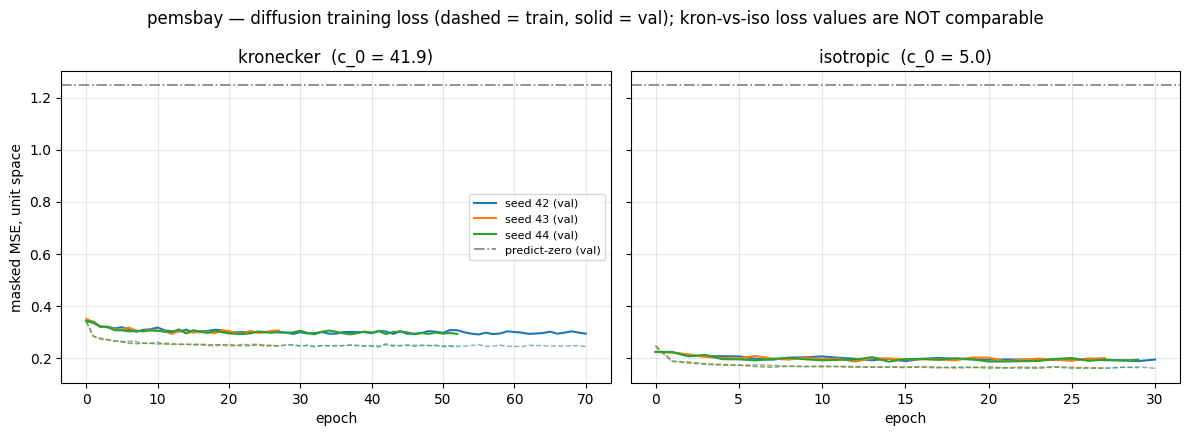

In [10]:
LOGDIR = Path("logs/20260610/diffusion")
RE_EPOCH = re.compile(r"^epoch (\d{3})\s+train=([\d.]+)\s+val=([\d.]+)")
RE_CURVE = re.compile(r"\[recon\] curve mae \(t->0\): (.+)")
RE_GEN = re.compile(r"\[recon\] gen mae=([\d.]+) mse=([\d.]+) "
                    r"\(h3=([\d.]+), h6=([\d.]+), h12=([\d.]+)\)\s+WI90=([\d.]+)\s+cov=([\d.]+)")
RE_W1 = re.compile(r"\[w1\] (\d+) clean windows x\d+ \(=([\d.]+) of val\)\s+mean W1=([\d.]+) ED=([\d.]+)")
RE_STOP = re.compile(r"early stop at epoch (\d+) \(patience=\d+, best_val=([\d.]+)\)")
RE_SIGMA = re.compile(r"\[train_diffusion\] train=\d+\s+val=\d+\s+sigma_r=([\d.]+)")
RE_C0 = re.compile(r"schedule c_0 auto-derived = ([\d.]+)")

def parse_log(rundir):
    log = max(rundir.glob("*.out"), key=lambda p: p.stat().st_size)
    run = {"epochs": [], "train": [], "val": [], "recon": [], "w1": [],
           "curve": None, "stop": None, "best_val": None, "sigma_r": None,
           "c0": None, "log": log.name}
    ep = None
    for line in log.read_text().splitlines():
        if (m := RE_EPOCH.match(line)):
            ep = int(m.group(1))
            run["epochs"].append(ep)
            run["train"].append(float(m.group(2)))
            run["val"].append(float(m.group(3)))
        elif (m := RE_CURVE.search(line)):
            run["curve"] = [(float(t), float(v)) for t, v in re.findall(r"([\d.]+):([\d.]+)", m.group(1))]
        elif (m := RE_GEN.search(line)):
            run["recon"].append(dict(epoch=ep, mae=float(m.group(1)),
                                     wi90=float(m.group(6)), cov=float(m.group(7))))
        elif (m := RE_W1.search(line)):
            run["w1"].append(dict(epoch=ep, n=int(m.group(1)),
                                  w1=float(m.group(3)), ed=float(m.group(4))))
        elif (m := RE_STOP.search(line)):
            run["stop"] = int(m.group(1)); run["best_val"] = float(m.group(2))
        elif (m := RE_SIGMA.search(line)):
            run["sigma_r"] = float(m.group(1))
        elif (m := RE_C0.search(line)):
            run["c0"] = float(m.group(1))
    return run

runs = {(p, s): parse_log(LOGDIR / f"diffusion_{dataset}_{p}_seed{s}")
        for p in ["kronecker", "isotropic"] for s in [42, 43, 44]}

# predict-zero references per seed, from that seed's own residual cache
triv = {}
for s in [42, 43, 44]:
    dv = np.load(paths.residual_npz(dataset, "val", s))
    r_, m_ = dv["residuals"], dv["mask"].astype(bool)
    sig = runs[("kronecker", s)]["sigma_r"]
    rval = r_[m_].astype(np.float64)
    m32 = m_[:32]
    triv[s] = dict(loss=float((rval ** 2).mean() / sig ** 2),
                   mae_full=float(np.abs(rval).mean()),
                   mae_32=float(np.abs(r_[:32][m32].astype(np.float64)).mean()))
print("predict-zero val loss (unit space):",
      {s: round(triv[s]["loss"], 3) for s in [42, 43, 44]})

print(f"\n{'run':22s} {'epochs':>6s} {'stop':>5s} {'best val':>9s} {'% of pred-zero':>14s} "
      f"{'sigma_r':>8s} {'c_0':>6s}")
fracs = []
for (p, s), run in runs.items():
    frac = run["best_val"] / triv[s]["loss"]
    fracs.append(frac)
    print(f"{p + '/seed' + str(s):22s} {len(run['epochs']):>6d} {str(run['stop']):>5s} "
          f"{run['best_val']:>9.4f} {frac:>13.0%} {run['sigma_r']:>8.4f} {run['c0']:>6.1f}")
best_frac_lo, best_frac_hi = min(fracs), max(fracs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
trivmean = np.mean([triv[s]["loss"] for s in [42, 43, 44]])
for ax, p in zip(axes, ["kronecker", "isotropic"]):
    for s, c in zip([42, 43, 44], ["C0", "C1", "C2"]):
        run = runs[(p, s)]
        ax.plot(run["epochs"], run["train"], c=c, ls="--", lw=1, alpha=0.6)
        ax.plot(run["epochs"], run["val"], c=c, lw=1.5, label=f"seed {s} (val)")
    ax.axhline(trivmean, color="gray", ls="-.", lw=1.2, label="predict-zero (val)")
    ax.set_title(f"{p}  (c_0 = {runs[(p, 42)]['c0']:.1f})")
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("masked MSE, unit space")
axes[0].legend(fontsize=8)
fig.suptitle(dataset + " — diffusion training loss (dashed = train, solid = val); "
             "kron-vs-iso loss values are NOT comparable")
plt.tight_layout()
plt.show()


**What this means:** all six runs **genuinely learn** — the best validation loss lands at roughly **19–23% of the predict-zero level**, train and val track each other with no divergence, and every run early-stopped well before the 200-epoch cap (the isotropic runs as early as epoch ~27–30, the kronecker ones later). Seeds agree on best-val to within a few percent. Note the validation curves flatten quickly: most of the drop happens in the first ~10 epochs, which matches the other datasets.

(Reminder: the kron panel's higher loss values do **not** mean kron is worse — different schedule, different task. Cross-prior comparisons only on the raw-unit metrics next.)

### in-training sample quality — the [recon] diagnostic

Every 10 epochs, training freezes **one fixed batch = the first 32 val windows**, noises it to t = T, and runs a deterministic (eta = 0) 100-step reverse pass, 20 samples per window. Three things to know before reading the plots:

- this is effectively a **fresh conditional sample, not a round-trip**: at t = T no information about the specific residual survives (by design). So the "curve mae" *rising* as t → 0 is the sample **committing to its own plausible outcome**, not a failure.
- **gen MAE** is the error of the 20-sample *mean* vs the true residual, raw mph. The honest yardstick is predict-zero **on the same 32 windows** — and for PEMS-BAY this fixed batch happens to be ~40% *easier* than the average val window, so comparing gen MAE to the full-val mean |R| would flatter the model. We plot the correct line.
- **WI90 / coverage** here use eta = 0, which *structurally under-covers* (deterministic samples cluster too tightly; ~0.6–0.86 observed vs the 0.90 target). These are trend curves, not calibration verdicts — test-time sampling uses eta = 1.


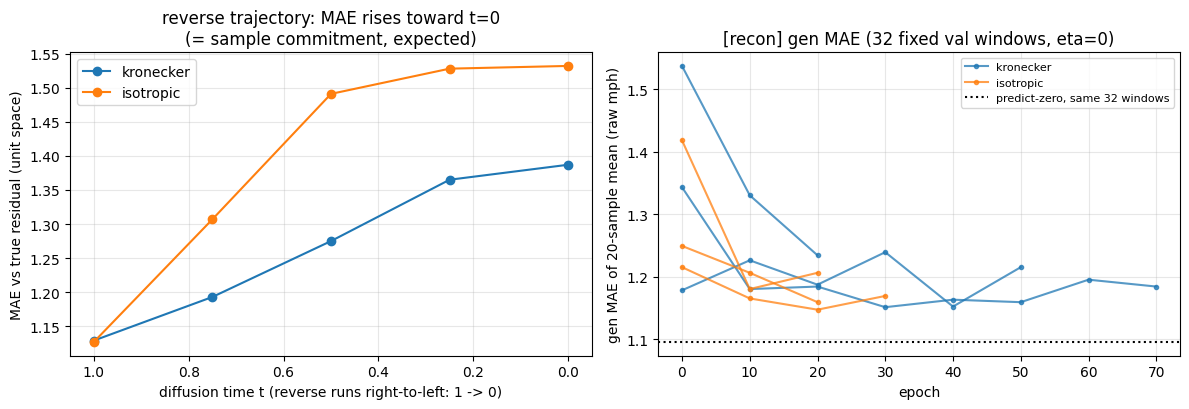

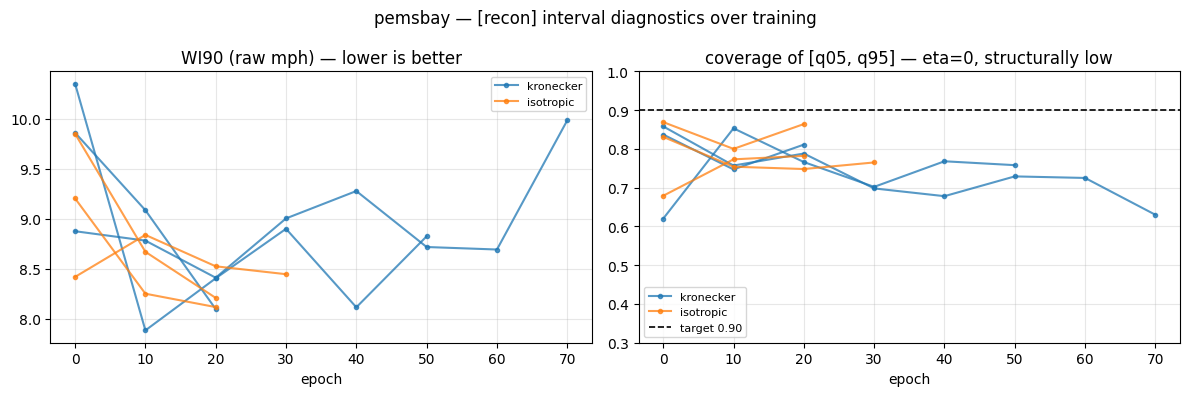

predict-zero mean|R|: full val = 1.77 mph, first-32-window batch = 1.11 mph (the recon batch is ~37% easier than average)

final gen MAE vs predict-zero on the SAME 32 windows:
  kronecker/seed42: 1.184 / 1.115 = 1.06x
  kronecker/seed43: 1.234 / 1.085 = 1.14x
  kronecker/seed44: 1.215 / 1.086 = 1.12x
  isotropic/seed42: 1.169 / 1.115 = 1.05x
  isotropic/seed43: 1.206 / 1.085 = 1.11x
  isotropic/seed44: 1.159 / 1.086 = 1.07x


In [11]:
# left: what one reverse trajectory looks like (final [recon] of seed 42, both priors)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for p, c in [("kronecker", "C0"), ("isotropic", "C1")]:
    cur = runs[(p, 42)]["curve"]
    ts = [t for t, _ in cur]; ms = [m for _, m in cur]
    axes[0].plot(ts, ms, "o-", color=c, label=p)
axes[0].invert_xaxis()
axes[0].set_xlabel("diffusion time t (reverse runs right-to-left: 1 -> 0)")
axes[0].set_ylabel("MAE vs true residual (unit space)")
axes[0].set_title("reverse trajectory: MAE rises toward t=0\n(= sample commitment, expected)")
axes[0].legend(); axes[0].grid(alpha=0.3)

# right: gen MAE over training
mae32 = np.mean([triv[s]["mae_32"] for s in [42, 43, 44]])
for p, c in [("kronecker", "C0"), ("isotropic", "C1")]:
    for k, s in enumerate([42, 43, 44]):
        rec = runs[(p, s)]["recon"]
        axes[1].plot([r["epoch"] for r in rec], [r["mae"] for r in rec],
                     c=c, marker="o", ms=3, alpha=0.75, label=p if k == 0 else None)
axes[1].axhline(mae32, color="k", ls=":", lw=1.5, label="predict-zero, same 32 windows")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("gen MAE of 20-sample mean (raw mph)")
axes[1].set_title("[recon] gen MAE (32 fixed val windows, eta=0)")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# WI90 + coverage
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p, c in [("kronecker", "C0"), ("isotropic", "C1")]:
    for k, s in enumerate([42, 43, 44]):
        rec = runs[(p, s)]["recon"]
        eps = [r["epoch"] for r in rec]
        axes[0].plot(eps, [r["wi90"] for r in rec], c=c, marker="o", ms=3, alpha=0.75,
                     label=p if k == 0 else None)
        axes[1].plot(eps, [r["cov"] for r in rec], c=c, marker="o", ms=3, alpha=0.75,
                     label=p if k == 0 else None)
axes[1].axhline(0.90, color="k", ls="--", lw=1.2, label="target 0.90")
axes[1].set_ylim(0.3, 1.0)
axes[0].set_title("WI90 (raw mph) — lower is better")
axes[1].set_title("coverage of [q05, q95] — eta=0, structurally low")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle(dataset + " — [recon] interval diagnostics over training")
plt.tight_layout()
plt.show()

print(f"predict-zero mean|R|: full val = {triv[42]['mae_full']:.2f} mph, "
      f"first-32-window batch = {triv[42]['mae_32']:.2f} mph "
      f"(the recon batch is ~{(1 - triv[42]['mae_32'] / triv[42]['mae_full']) * 100:.0f}% easier than average)")
print("\nfinal gen MAE vs predict-zero on the SAME 32 windows:")
gen_ratios = {}
for (p, s), run in runs.items():
    r = run["recon"][-1]["mae"] / triv[s]["mae_32"]
    gen_ratios[(p, s)] = r
    print(f"  {p}/seed{s}: {run['recon'][-1]['mae']:.3f} / {triv[s]['mae_32']:.3f} = {r:.2f}x")


**What this means:** the final gen MAE sits at about **1.1x the predict-zero baseline on the same windows** — i.e. the sample *mean* is roughly as accurate as doing nothing. That is not a scandal; it is close to **by construction**: the diffusion scores *residuals*, so its mean cannot beat the backbone by much, and point accuracy was never the value proposition. The value claim rests entirely on the *distributional* metrics — calibration, Winkler, CRPS, W1. (Averaged over seeds the ratio is 1.11x kron / 1.08x iso here; across all three datasets the seed-averaged ratios run 0.93–1.11x.)

Coverage climbing toward ~0.7–0.85 but never 0.90 is the expected eta = 0 artifact described above — do not read it as the test-time calibration.

### distribution match — the [w1] diagnostic

Every 20 epochs: **sliced Wasserstein-1** and **energy distance** between generated and true residuals, with eta = 1 (proper stochastic sampling) but only **1 sample per window**, on the **chronologically first 512 clean val windows**. Two honest footnotes: the log line prints "=1.00 of val", but that is the *clean fraction* (PEMS-BAY has no missing data, so all windows are clean) — the 512 actually used are ~10% of the 5189 val windows, and "first 512" is a chronological selection. With 1 sample per window and only 2–4 evaluation points per run, this is **trend-quality evidence, far too thin for ranking the two priors**.


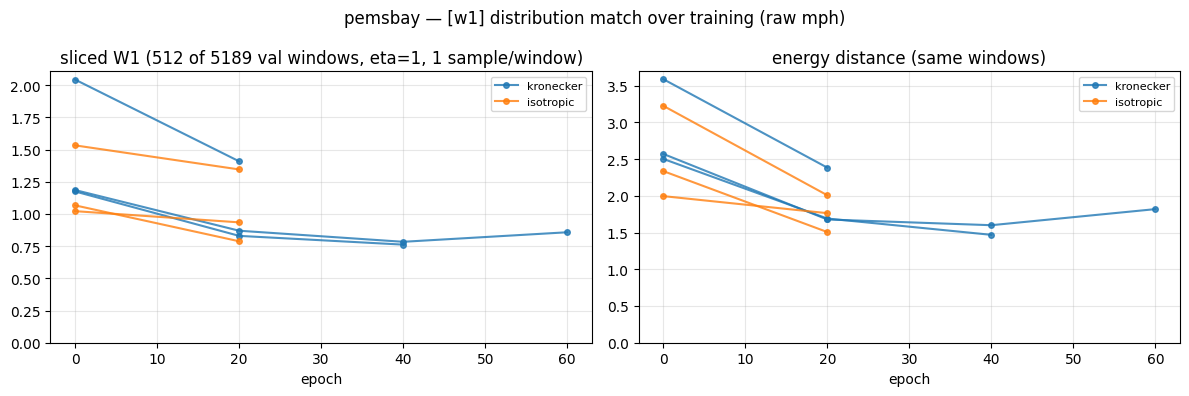

sliced W1, first -> last eval per run:
  kronecker/seed42: 1.186 -> 0.858   (+28% improvement, 4 eval points)
  kronecker/seed43: 2.044 -> 1.409   (+31% improvement, 2 eval points)
  kronecker/seed44: 1.175 -> 0.762   (+35% improvement, 3 eval points)
  isotropic/seed42: 1.022 -> 0.935   (+9% improvement, 2 eval points)
  isotropic/seed43: 1.533 -> 1.346   (+12% improvement, 2 eval points)
  isotropic/seed44: 1.067 -> 0.788   (+26% improvement, 2 eval points)
mean improvement over the 6 runs: 23%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p, c in [("kronecker", "C0"), ("isotropic", "C1")]:
    for k, s in enumerate([42, 43, 44]):
        w = runs[(p, s)]["w1"]
        eps = [r["epoch"] for r in w]
        axes[0].plot(eps, [r["w1"] for r in w], c=c, marker="o", ms=4, alpha=0.8,
                     label=p if k == 0 else None)
        axes[1].plot(eps, [r["ed"] for r in w], c=c, marker="o", ms=4, alpha=0.8,
                     label=p if k == 0 else None)
n_w1 = runs[("kronecker", 42)]["w1"][0]["n"]
axes[0].set_title(f"sliced W1 ({n_w1} of 5189 val windows, eta=1, 1 sample/window)")
axes[1].set_title("energy distance (same windows)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylim(bottom=0); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle(dataset + " — [w1] distribution match over training (raw mph)")
plt.tight_layout()
plt.show()

print("sliced W1, first -> last eval per run:")
drops = []
for (p, s), run in runs.items():
    w = run["w1"]
    d = (w[0]["w1"] - w[-1]["w1"]) / w[0]["w1"]
    drops.append(d)
    print(f"  {p}/seed{s}: {w[0]['w1']:.3f} -> {w[-1]['w1']:.3f}   "
          f"({d:+.0%} improvement, {len(w)} eval points)")
w1_mean_drop = float(np.mean(drops))
print(f"mean improvement over the 6 runs: {w1_mean_drop:.0%}")


**What this means:** the generated residual *distribution* moves toward the real one as training progresses — W1 drops by roughly a quarter on average (across all 18 runs of the experiment, 16 improve; dataset-mean drops are 33% METR-LA, 20% PEMS08F, ~24% PEMS-BAY). That is the direct evidence the model is learning distribution shape, not just denoising. But with the tiny sample budget noted above, the kron and iso curves overlap within noise — **the in-training logs do not support a kron-beats-iso claim** on this dataset; the test evaluation has to settle that (and it cannot yet — next section).


> 🔧 **UPDATE (2026-06-11 16:25 CEST):** the eval-schedule bug described below was **fixed and deployed today** (commit `8803302`): `eval_diffusion.py` now rebuilds the reverse schedule via `FCPSSchedule.for_prior` (the training schedule), and `train_diffusion.py` persists the derived `c_0` into `config.json`. all 18 corrected eval jobs were resubmitted to the cluster; the old contaminated outputs were moved to `results/eval/20260610_buggy_c0/`. **the cell below now auto-loads the CORRECTED results if present, else the preserved buggy ones (clearly labeled)** — re-run it after a `sync_from_daic.sh`.

## 6. test results so far

> **eval bug — found and FIXED 2026-06-11 (commit `8803302`); see the UPDATE box above. the paragraph below explains what the bug was.**
> `scripts/eval_diffusion.py:90` rebuilds the reverse schedule from `config.json`'s `c_0 = 20000` — the *ignored CLI default* — instead of the auto-derived value training actually used (~41.9 kron / 5.0 iso here). The reverse chain at eval is therefore ~**480x (kron)** / **4000x (iso)** hotter than the schedule the models were trained on, and the distortion is *asymmetric between the two arms*, so even the kron-vs-iso ranking cannot be trusted. The 12 pre-fix `test_metrics.json` (METR-LA + PEMS08F) were moved to `eval/20260610_buggy_c0/`, the 6 contaminated PEMS-BAY jobs were cancelled, and all 18 evals were resubmitted on the fixed code. The during-training [recon]/[w1] numbers above used the correct schedule and are valid.

PEMS-BAY's corrected test evaluation (full test split, K = 30 samples, 50 steps, eta = 1, alpha = 0.1) is queued behind the headline datasets (10 h walltime; likely early-morning). The cell below loads whatever has synced (preferring corrected over buggy) and stays graceful if nothing has — right now nothing has, so it prints PENDING.


In [13]:
# read the test metrics. prefer the CORRECTED eval (post-fix, schedule rebuilt via
# FCPSSchedule.for_prior); fall back to the preserved buggy run so the qualitative
# story stays visible until the corrected numbers land. re-run after a sync_from_daic.
if "note" not in globals():            # some notebooks have no section-7 summary table
    def note(*a, **k):
        pass
corrected = Path("results/eval/20260610") / dataset
buggy = Path("results/eval/20260610_buggy_c0") / dataset

def _load(evdir):
    out = []
    for pn in ["kronecker", "isotropic"]:
        for s in [42, 43, 44]:
            f = evdir / pn / f"seed{s}" / "test_metrics.json"
            if f.exists():
                out.append(json.loads(f.read_text()))
    return out

recs = _load(corrected)
is_corrected = bool(recs)
if not recs:
    recs = _load(buggy)

if not recs:
    print(f"no test_metrics.json for {dataset} yet — corrected eval still running. PENDING.")
    note("test metrics", "PENDING",
         "corrected eval jobs submitted 2026-06-11 16:25; sync + re-run this cell once they land")
else:
    # backbone-only reference: predict zero residual on the test split, per seed
    bb = {}
    for s in sorted({r["seed"] for r in recs}):
        dte = np.load(paths.residual_npz(dataset, "test", s))
        bb[s] = float(np.abs(dte["residuals"][dte["mask"].astype(bool)].astype(np.float64)).mean())

    if is_corrected:
        print(">> CORRECTED eval (schedule = FCPSSchedule.for_prior, the training schedule) — quotable\n")
    else:
        print("!! CONTAMINATED by the c_0=20000 eval bug. corrected re-run in flight; "
              "shown for the qualitative story only !!\n")
    print(f"{'prior':10s} {'seed':>4s} {'ckpt ep':>7s} {'MAE':>7s} {'Winkler':>8s} "
          f"{'coverage':>8s} {'CRPS':>6s} {'W1*':>7s}")
    for r in recs:
        print(f"{r['prior']:10s} {r['seed']:>4d} {r['ckpt_epoch']:>7d} {r['mae']:>7.2f} "
              f"{r['winkler']:>8.1f} {r['coverage']:>8.3f} {r['crps']:>6.2f} {r['w1']:>7.2f}")
    print(f"{'backbone':10s}   (predict-zero residual)   MAE: "
          + ",  ".join(f"seed{s} = {v:.2f}" for s, v in bb.items()))

    print("\nper-prior mean +- std over seeds:")
    cov_kron = None
    for pn in ["kronecker", "isotropic"]:
        sub = [r for r in recs if r["prior"] == pn]
        if not sub:
            continue
        agg = {k: (float(np.mean([r[k] for r in sub])), float(np.std([r[k] for r in sub])))
               for k in ["mae", "winkler", "coverage", "crps", "w1"]}
        if pn == "kronecker":
            cov_kron = agg["coverage"][0]
        print(f"  {pn:10s} MAE {agg['mae'][0]:.2f}+-{agg['mae'][1]:.2f}   "
              f"Winkler {agg['winkler'][0]:.1f}+-{agg['winkler'][1]:.1f}   "
              f"coverage {agg['coverage'][0]:.3f}+-{agg['coverage'][1]:.3f}   "
              f"CRPS {agg['crps'][0]:.2f}+-{agg['crps'][1]:.2f}   W1* {agg['w1'][0]:.2f}+-{agg['w1'][1]:.2f}")

    r0 = recs[0]
    print(f"\n* W1 is computed on only the first {r0['w1_clean_windows']} clean test windows "
          f"({r0['w1_clean_windows'] / r0['n_test_windows']:.0%} of test; the stored "
          f"'w1_frac_of_test={r0['w1_frac_of_test']:.2f}' is the clean FRACTION, not the fraction used)")

    if is_corrected:
        note("test metrics (CORRECTED eval, post-fix schedule)", "OK",
             "quotable kron-vs-iso comparison; see per-prior aggregates above")
    else:
        note("test metrics present but CONTAMINATED by the c_0=20000 eval bug", "CAVEAT",
             "reverse ran hotter than training, asymmetric between arms - corrected re-run submitted, replace when it lands")
        if cov_kron is not None:
            note(f"test coverage (kron, buggy) = {cov_kron:.3f} vs 0.90 target", "CAVEAT",
                 "do not interpret until the corrected eval lands")

# a single status for notebooks that build one hardcoded summary table at the end
test_status = "PENDING" if not recs else ("OK (corrected)" if is_corrected else "CAVEAT (buggy)")


no test_metrics.json for pemsbay yet — corrected eval still running. PENDING.


**Context from the other datasets (same bug, so same caveat — quoted only to set expectations):** on METR-LA the contaminated table read kron MAE 3.730±0.027 vs iso 3.620±0.067 (backbone 3.309), with kron ahead on Winkler (31.70 vs 32.90), CRPS (2.96 vs 3.03) and W1 (1.77 vs 2.18 — though W1 used only the first 114 clean windows, 1.7% of test), coverage 0.916 vs 0.922 at the 0.90 target. PEMS08F told a similar story with kron coverage 0.849 (under). None of it is quotable until the evals are re-run with the correct schedule.

For PEMS-BAY specifically, the section-2 gate failure makes a **prediction**: the prior scale is ~12% too small for val/test, so expect **under-coverage** here even after the bug fix. If the fixed eval shows roughly that, the limitation story is coherent end to end; the interesting question is whether the structured arm degrades more gracefully than the isotropic one.


## 7. summary — every check on one screen


In [14]:
checks = [
    ("data integrity (nan/inf/mask/float16)", "PASS",
     "zero nan/inf in all splits; mask fully valid; float16 storage numerically harmless"),
    ("sigma_r matches the training log", "PASS",
     f"{sigma_r:.4f} mph computed here vs 3.5537 in the log"),
    ("residual tails", "HEAVY",
     f"excess kurtosis {exkurt:.1f}; implied student-t nu = {nu_implied:.2f} "
     f"(supports the nu~4.2 pivot; caveat: left skew {skew:.1f})"),
    ("train-vs-val variance gate (<10%)", "FAIL",
     f"worst horizon {gate_worst:.3f} (all 3 seeds fail); val ~12% noisier -> "
     "prior scale too small on val/test; the agreed limitation case"),
    ("Sigma_T well-formed (symmetric, PSD)", "PASS",
     f"raw eigenvalue range [{mu_raw.min():.4f}, {mu_raw.max():.3f}]"),
    ("kappa cap on cond(Sigma_T)", "BINDS",
     f"raw cond {cond_raw:.0f} -> capped 40; {n_floored}/12 modes floored "
     "(only dataset where the cap binds)"),
    ("graph connectivity", "BENIGN",
     f"{n_comp} BFS components = giant {sizes[0]} + {n_isolated} isolated sensors; "
     "eigenvalue count misleads (isolated nodes sit at eigenvalue 1)"),
    ("FCPS mixing 2*c_bar(T)*theta_min >= 5", "PASS",
     f"= {mix_lhs:.1f} (x{mix_lhs / 5:.1f} margin by construction); "
     f"slowest mode 99% mixed at t* = {tstar_slow:.2f}; c_0 = {sch.c_0:.1f} auto-derived, "
     "config.json's 20000 is the ignored default"),
    ("forward noising matches the closed form", "PASS",
     f"worst pooled z = {worst_z:.2f} here (full 360-test suite: 3.33) — MC-noise level"),
    ("training learns (all 6 runs)", "PASS",
     f"best val loss {best_frac_lo:.0%}-{best_frac_hi:.0%} of predict-zero; "
     "no train/val divergence; all early-stopped; seeds consistent"),
    ("point accuracy of samples", "AS EXPECTED",
     f"gen MAE plateaus at {min(gen_ratios.values()):.2f}-{max(gen_ratios.values()):.2f}x "
     "predict-zero on the same 32 windows — value must come from distributional metrics"),
    ("distribution match trend (W1)", "IMPROVES",
     f"mean {w1_mean_drop:.0%} drop first->last; trend evidence only, too thin for prior ranking"),
    ("kron vs iso during training", "NO WINNER",
     "raw-unit metrics overlap within noise; loss values not comparable across arms"),
    ("test metrics", test_status,
     "c_0=20000 eval bug FIXED today (8803302); buggy outputs moved to eval/20260610_buggy_c0; "
     "corrected eval re-running; this cell auto-loads corrected-or-buggy (see the section-6 banner)"),
]
wmax = max(len(c[0]) for c in checks)
print(f"{'check':{wmax}s}  {'status':12s}  meaning")
print("-" * (wmax + 90))
for name, status, meaning in checks:
    print(f"{name:{wmax}s}  {status:12s}  {meaning}")


check                                    status        meaning
---------------------------------------------------------------------------------------------------------------------------------
data integrity (nan/inf/mask/float16)    PASS          zero nan/inf in all splits; mask fully valid; float16 storage numerically harmless
sigma_r matches the training log         PASS          3.5537 mph computed here vs 3.5537 in the log
residual tails                           HEAVY         excess kurtosis 39.9; implied student-t nu = 4.15 (supports the nu~4.2 pivot; caveat: left skew -2.3)
train-vs-val variance gate (<10%)        FAIL          worst horizon 0.266 (all 3 seeds fail); val ~12% noisier -> prior scale too small on val/test; the agreed limitation case
Sigma_T well-formed (symmetric, PSD)     PASS          raw eigenvalue range [0.0520, 8.372]
kappa cap on cond(Sigma_T)               BINDS         raw cond 161 -> capped 40; 8/12 modes floored (only dataset where the cap binds)
graph 

### closing words

The PEMS-BAY machinery is **sound**: the data is clean, the prior matrices are exactly what the recipe says, the noising process provably implements the math, and all six models train stably and learn real distributional structure. The two open items are *external* to this dataset's pipeline:

1. **the eval bug** — the reverse-schedule rebuild in `eval_diffusion.py` was fixed today (commit `8803302`) and all test evals were resubmitted; quote test numbers only once the corrected PEMS-BAY run lands.
2. **the gate failure** — not fixable and not meant to be fixed: PEMS-BAY's val/test period is genuinely ~12% noisier than train. The thesis uses this as the limitation case study; the post-fix test coverage will quantify how each prior degrades under that distribution step.

And the tails result (excess kurtosis ≈ 40, implied nu ≈ 4.15) is this dataset's vote for the structured **heavy-tailed** prior pivot: the gaussian prior is the right covariance with the wrong tail.
